In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder 
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report,precision_score
# regular expression modeule : re
import re
import string

from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer
from wordcloud import WordCloud


In [2]:
df=pd.read_csv(r"c:\Users\nabee\Downloads\Spam_SMS.csv")
df

,Class,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
...,...,...
5569,spam,This is the 2nd time we have tried 2 contact u...
5570,ham,Will ü b going to esplanade fr home?
5571,ham,"Pity, * was in mood for that. So...any other s..."
5572,ham,The guy did some bitching but I acted like i'd...


In [3]:
df.head(4)

,Class,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...


In [4]:
df.tail()

,Class,Message
5569,spam,This is the 2nd time we have tried 2 contact u...
5570,ham,Will ü b going to esplanade fr home?
5571,ham,"Pity, * was in mood for that. So...any other s..."
5572,ham,The guy did some bitching but I acted like i'd...
5573,ham,Rofl. Its true to its name


In [5]:
df.columns

Index(['Class', 'Message'], dtype='object')

In [6]:
df.shape

(5574, 2)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5574 entries, 0 to 5573
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   Class    5574 non-null   object
 1   Message  5574 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB


In [8]:
df.isnull().sum()

Class      0
Message    0
dtype: int64

In [9]:
scale=LabelEncoder()

In [10]:
df['Class']=scale.fit_transform(df['Class'])
df['Class']

0       0
1       0
2       1
3       0
4       0
       ..
5569    1
5570    0
5571    0
5572    0
5573    0
Name: Class, Length: 5574, dtype: int64

In [11]:
def wordopt(Message):
    msg=str(Message).lower()
    # 1. Remove URLs first (so punctuation inside URLs doesn't break matching)
    msg=re.sub(r'https?://\S+|www\.S+',' ',msg)
    # 2. Remove HTML tags and bracketed content
    msg=re.sub(r'<.*?>',' ',msg)
    msg=re.sub(r'\[.*?]',' ',msg)
   # 3. Remove words containing numbers (e.g., 'v2', 'user123')
    msg=re.sub(r'\w*\d\w*',' ',msg)
    # 4. Remove punctuation
    msg=re.sub('[%s]' % re.escape(string.punctuation),' ',msg)
    # Clean up all whitespace (newlines, tabs, multiple spaces) in ONE step
    msg=re.sub(r'\s+',' ',msg).strip()
    return msg

In [12]:
# def wordopt(Message):
#     msg=str(Message).lower()
#     msg=re.sub(r'https?://\S+|www\.S+',' ',msg)
#     msg=re.sub(r'<.*?>',' ',msg)
#     msg=re.sub(r'\[.*?]',' ',msg)
#     msg=re.sub(r'\w*\d\w*',' ',msg)
#     msg=re.sub('[%s]' % re.escape(string.punctuation,' ',msg))
#     msg=re.sub(r'\s+',' ',msg).strip()
#     return msg

In [13]:
df['Message']=df['Message'].apply(wordopt)

In [14]:
# def wordopt(Message):
#     msg=str(Message).lower()
#     msg=re.sub(r'https?://\S+|www\.S+',' ',msg)
#     msg=re.sub(r'<.*?>',' ',msg)x=df
#     msg=re.sub(r'\[.*?]',' ',msg)
#     msg=re.sub(r'w*\d\w*',' ',msg)
#     msg=re.sub('[%s]' % re.escape(string.punctuation),' ',msg)
#     msg=re.sub(r'\s+',' ',msg).strip()
#     return msg

# df['Message'] = df['Message'].apply(wordopt)

# msg_com=' '.join(df['Message'].dropna().astype(str).str.strip())
# if not msg_com.strip():
#     print("no words found")
# else:
#     plt.figure(figsize=(20,15),facecolor='None')
#     wordcloud=WordCloud(max_words=500,width=1300,height=500).generate(msg_com)
#     plt.imshow(wordcloud,interpolation='bilinear')
#     plt.axis=('off')
#     plt.title(fontsize=25,pad=30)
#     plt.show()   

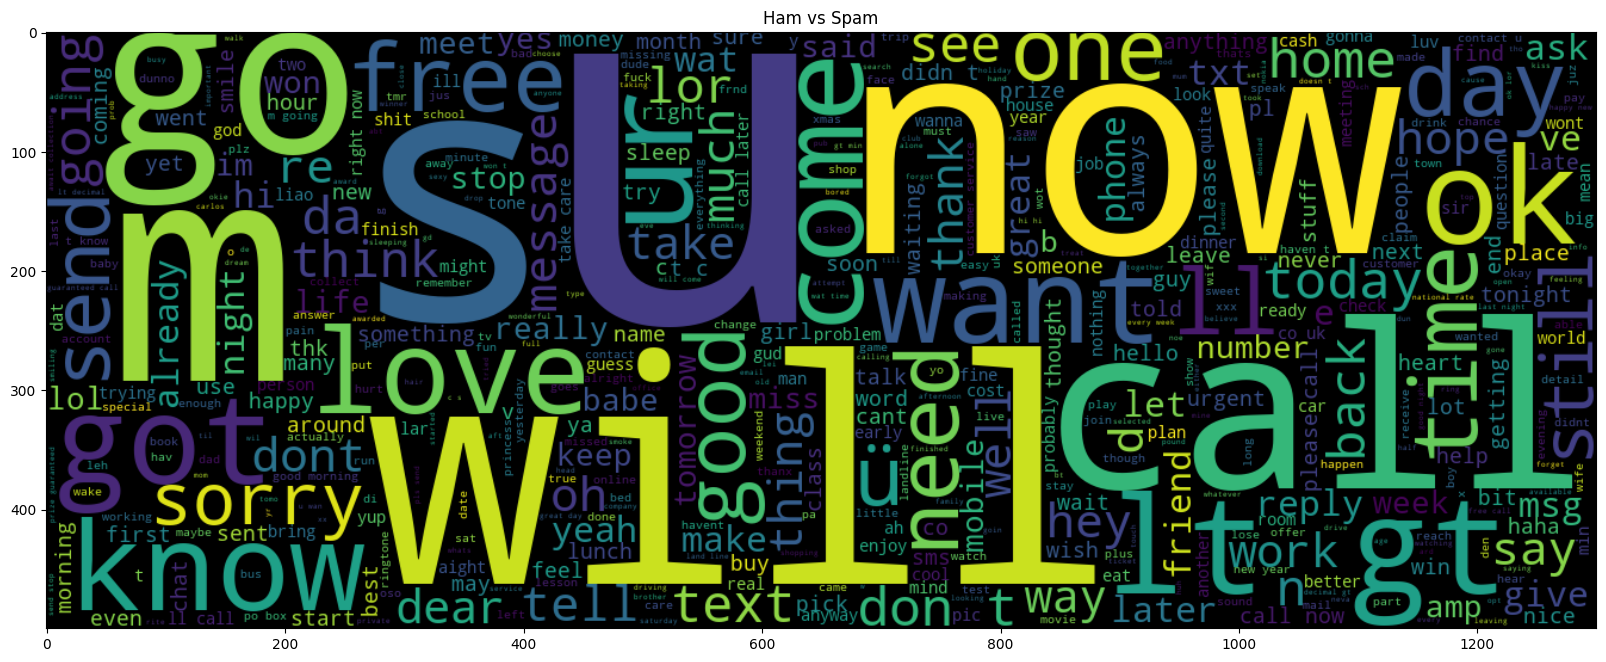

In [15]:
msg_com=' '.join(df['Message'].dropna().astype(str).str.strip())

if not msg_com.strip():
    print("No words found the dataset to plot in wordcloud")
else:
    plt.figure(figsize=(20,15),facecolor='None')
    wordcloud=WordCloud(max_words=500,width=1300,height=500).generate(msg_com)
    plt.imshow(wordcloud,interpolation='bilinear')
    plt.axis=('off')
    plt.title('Ham vs Spam')
    plt.show()
    

In [16]:
x=df['Message']
x

0       go until jurong point crazy available only in ...
1                                 ok lar joking wif u oni
2       free entry in a wkly comp to win fa cup final ...
3             u dun say so early hor u c already then say
4       nah i don t think he goes to usf he lives arou...
                              ...                        
5569    this is the time we have tried contact u u hav...
5570                  will ü b going to esplanade fr home
5571    pity was in mood for that so any other suggest...
5572    the guy did some bitching but i acted like i d...
5573                            rofl its true to its name
Name: Message, Length: 5574, dtype: object

In [17]:
y=df['Class']
y

0       0
1       0
2       1
3       0
4       0
       ..
5569    1
5570    0
5571    0
5572    0
5573    0
Name: Class, Length: 5574, dtype: int64

In [18]:
x_train,x_test,y_train,y_test=train_test_split(x,y,random_state=42,test_size=0.25)

In [19]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [20]:
vectorizer=TfidfVectorizer()
xv_train=vectorizer.fit_transform(x_train)
xv_test=vectorizer.transform(x_test)

In [21]:
xv_train.shape

(4180, 6491)

In [22]:
xv_test.shape

(1394, 6491)

In [23]:
lr=LogisticRegression()
lr.fit(xv_train,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [24]:
y_pred=lr.predict(xv_test)

In [25]:
accu=accuracy_score(y_test,y_pred)
accu

0.9684361549497847

In [26]:
pt=[]
for i in [lr]:
    i.fit(xv_train,y_train)
    pt.append(round(accuracy_score(y_test,i.predict(xv_test))*100,2))
    print(pt)


[96.84]


In [27]:
def wordopt(Message):
    msg=str(Message).lower()
    msg=re.sub(r'https?://\S+|www\.S+',' ',msg)
    msg=re.sub(r'<.*?>',' ',msg)
    msg=re.sub(r'\[.*?]',' ',msg)
    msg=re.sub(r'\w*\d\w*',' ',msg)
    msg=re.sub('[%s]' % re.escape(string.punctuation),'', msg)
    msg=re.sub(r'\s+',' ',msg).strip()
    return msg

In [28]:
df['Message']=df['Message'].apply(wordopt)


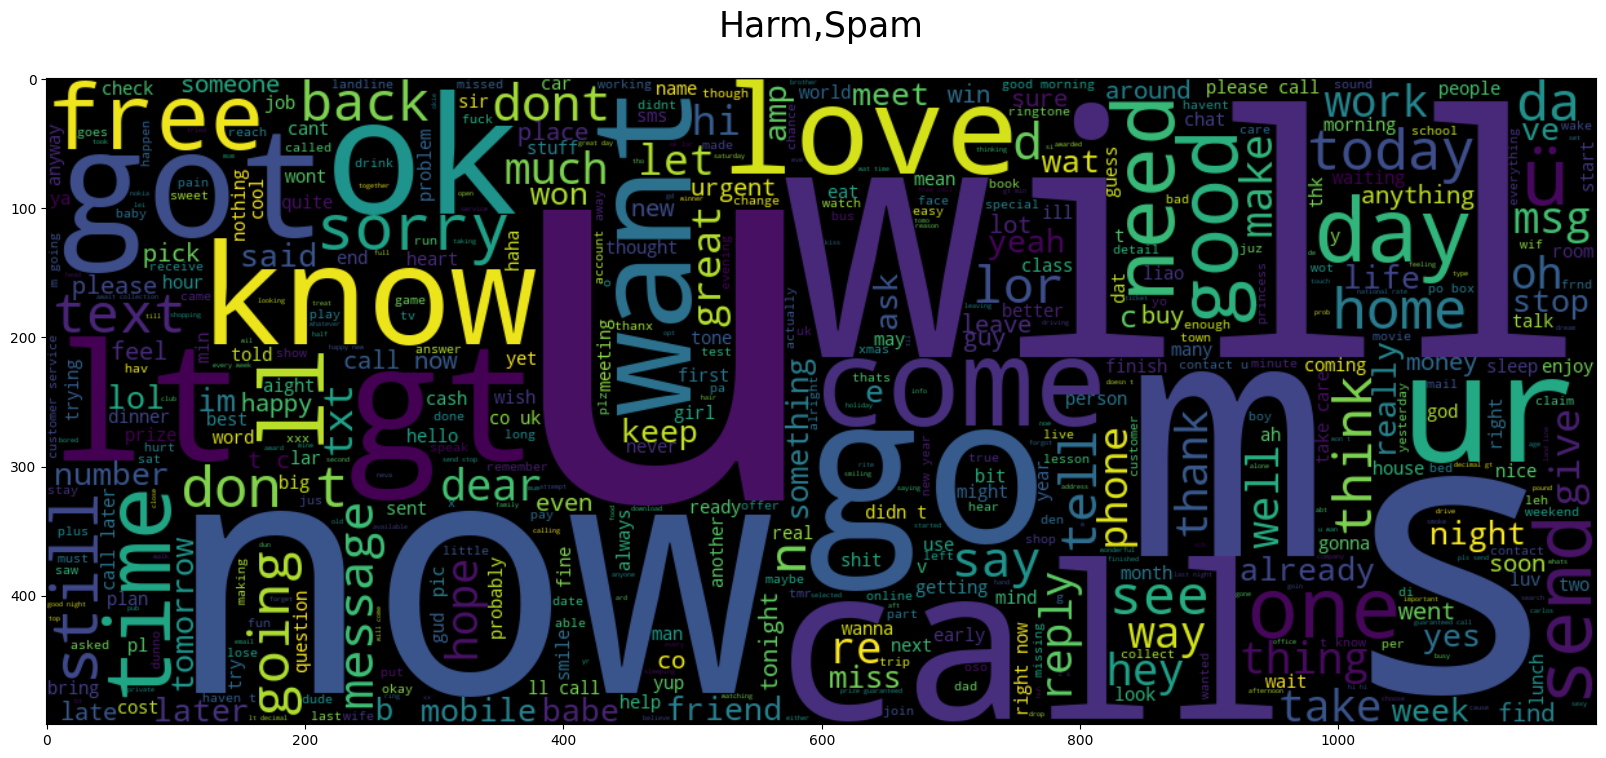

In [29]:
msg_com=' '.join(df['Message'].dropna().astype(str).str.strip())

if not msg_com.strip():
    print("no find words data set")
else:
    plt.figure(figsize=(20,15),facecolor='None')
    wordcloud=WordCloud(max_words=500,width=1200,height=500).generate(msg_com)
    plt.imshow(wordcloud,interpolation='bilinear')
    plt.axis=('off')
    plt.title("Harm,Spam",fontsize=25,pad=30)
    plt.show()    

In [ ]:
x=df['Message']
y=df['Class']

In [ ]:
x_train,x_test,y_train,y_test=train_test_split(x,y,random_state=42,test_size=0.25)

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
vectorizer=TfidfVectorizer()

In [ ]:
xv_train=vectorizer.fit_transform(x_train)
xv_test=vectorizer.transform(x_test)

In [ ]:
lr=LogisticRegression()
lr.fit(xv_train,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [ ]:
y_pred=lr.predict(xv_test)

In [ ]:
acc=accuracy_score(y_test,y_pred)
acc

0.9684361549497847

In [ ]:
pt=[]
for i in [lr]:
    i.fit(xv_train,y_train)
    pt.append(round(accuracy_score(y_test,i.predict(xv_test))*100,2))
print(pt)

[96.84]


In [ ]:
pd.set_option('display.max_colwidth',None)

In [ ]:
x.head(4)

0                    go until jurong point crazy available only in bugis n great world la e buffet cine there got amore wat
1                                                                                                   ok lar joking wif u oni
2    free entry in a wkly comp to win fa cup final tkts may text fa to to receive entry question std txt rate t c s apply s
3                                                                               u dun say so early hor u c already then say
Name: Message, dtype: object

In [ ]:
y.head(4)

0    0
1    0
2    1
3    0
Name: Class, dtype: int64

In [ ]:
sample=["""ok lar joking wif u oni"""]
sample_vector=vectorizer.transform(sample)
result=lr.predict(sample_vector)
print(result)
if (result == 0):
    print("positive review")
else:
    print("Negative review") 

    

[0]
positive review


In [ ]:
corpus= [
    "I love machine learning",
    "Machine learning is fun",
    "I love Python"
]
corpus_list=[doc.lower().replace(".","")for doc in corpus]
corpus_list

['i love machine learning', 'machine learning is fun', 'i love python']

In [ ]:
# Bow
corpus=["I love machine learning",
        "Machine learning is fun",
        "I love Python "]

corpus_list=[doc.lower().replace(".","") for doc in corpus]
corpus_list


['i love machine learning', 'machine learning is fun', 'i love python ']

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

vector=CountVectorizer()
count=vector.fit_transform(corpus_list)
print(vector.vocabulary_)

{'love': 3, 'machine': 4, 'learning': 2, 'is': 1, 'fun': 0, 'python': 5}


In [ ]:
df_ng=pd.DataFrame(
    count.toarray(),
    columns=vector.get_feature_names_out(),
    index=['Doc 1','Doc 2','Doc 3']
)
print(df_ng)

       fun  is  learning  love  machine  python
Doc 1    0   0         1     1        1       0
Doc 2    1   1         1     0        1       0
Doc 3    0   0         0     1        0       1


In [ ]:
# Bow 2
corpus=["Good good good  movie,highly recommend",
        "Bad bad movie ,tottaly teribble",
        "Good movie,bad actors"]
corpus_list=[doc.lower().replace(".","")for doc in corpus]
corpus_list

['good good good  movie,highly recommend',
 'bad bad movie ,tottaly teribble',
 'good movie,bad actors']

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
vector=CountVectorizer()
count=vector.fit_transform(corpus_list)
print(vector.vocabulary_)

{'good': 2, 'movie': 4, 'highly': 3, 'recommend': 5, 'bad': 1, 'tottaly': 7, 'teribble': 6, 'actors': 0}


In [ ]:
df_ng=pd.DataFrame(
    count.toarray(),
    columns=vector.get_feature_names_out(),
    index=['Doc 1','Doc 2','Doc 3']
)
print(df_ng)

       actors  bad  good  highly  movie  recommend  teribble  tottaly
Doc 1       0    0     3       1      1          1         0        0
Doc 2       0    2     0       0      1          0         1        1
Doc 3       1    1     1       0      1          0         0        0


In [ ]:
corpus=["The cat on the mat.",
        "The dog sat on the rug."
        "Cats and dogs are great pets.",
        "A cat and  a dog play together."]
process_list=[doc.lower().replace(".","")for doc in corpus]
process_list

['the cat on the mat',
 'the dog sat on the rugcats and dogs are great pets',
 'a cat and  a dog play together']

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
vec=CountVectorizer()
count=vec.fit_transform(process_list)
print(vec.vocabulary_)

{'the': 12, 'cat': 2, 'on': 7, 'mat': 6, 'dog': 3, 'sat': 11, 'rugcats': 10, 'and': 0, 'dogs': 4, 'are': 1, 'great': 5, 'pets': 8, 'play': 9, 'together': 13}


In [ ]:
df_ng=pd.DataFrame(
    count.toarray(),
    columns=vec.get_feature_names_out()

)
print(df_ng)

   and  are  cat  dog  dogs  great  mat  on  pets  play  rugcats  sat  the  \
0    0    0    1    0     0      0    1   1     0     0        0    0    2   
1    1    1    0    1     1      1    0   1     1     0        1    1    2   
2    1    0    1    1     0      0    0   0     0     1        0    0    0   

   together  
0         0  
1         0  
2         1  


In [ ]:
# binary
count_vec=CountVectorizer(binary=True)
count_vec.fit(process_list)
temp=count_vec.transform(["the dog sat on the rugcats and dogs are great pets"])

df_temp=pd.DataFrame(temp.toarray(),columns=count_vec.get_feature_names_out())
print(df_temp)

   and  are  cat  dog  dogs  great  mat  on  pets  play  rugcats  sat  the  \
0    1    1    0    1     1      1    0   1     1     0        1    1    1   

   together  
0         0  


In [ ]:
# Default (binary=False): Counts how many times each word appears in a document (e.g., $1, 2, 3$).binary=True: Tracks presence or absence only. If a word appears $1$ time or $100$ times, its value will strictly be $1$. If it doesn't appear, it stays $0$.

In [ ]:
corpus=["The cat on the mat.",
        "The dog sat on the rug."
        "Cats and dogs are great pets.",
        "A cat and  a dog play together."]

corpus_list=[doc.lower().replace(".","")for doc in corpus]
corpus_list



['the cat on the mat',
 'the dog sat on the rugcats and dogs are great pets',
 'a cat and  a dog play together']

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
tf_idf=TfidfVectorizer()
count=tf_idf.fit_transform(corpus_list)
print(tf_idf.vocabulary_)

{'the': 12, 'cat': 2, 'on': 7, 'mat': 6, 'dog': 3, 'sat': 11, 'rugcats': 10, 'and': 0, 'dogs': 4, 'are': 1, 'great': 5, 'pets': 8, 'play': 9, 'together': 13}


In [ ]:
df_ng=pd.DataFrame(
    count.toarray(),
    columns=tf_idf.get_feature_names_out()
)

print(df_ng.round(3))

     and    are    cat    dog   dogs  great    mat    on   pets   play  \
0  0.000  0.000  0.360  0.000  0.000  0.000  0.473  0.36  0.000  0.000   
1  0.240  0.315  0.000  0.240  0.315  0.315  0.000  0.24  0.315  0.000   
2  0.394  0.000  0.394  0.394  0.000  0.000  0.000  0.00  0.000  0.517   

   rugcats    sat    the  together  
0    0.000  0.000  0.719     0.000  
1    0.315  0.315  0.480     0.000  
2    0.000  0.000  0.000     0.517  


In [ ]:
import nltk
from nltk.corpus import brown
import string
words=brown.words()
clean=[w for w in words if w not in string.punctuation]

print(clean[:10])

['The', 'Fulton', 'County', 'Grand', 'Jury', 'said', 'Friday', 'an', 'investigation', 'of']


In [ ]:
# trail complete

df=pd.read_csv(r"c:\Users\nabee\Downloads\Spam_SMS.csv")
df

,Class,Message
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"
...,...,...
5569,spam,"This is the 2nd time we have tried 2 contact u. U have won the £750 Pound prize. 2 claim is easy, call 087187272008 NOW1! Only 10p per minute. BT-national-rate."
5570,ham,Will ü b going to esplanade fr home?
5571,ham,"Pity, * was in mood for that. So...any other suggestions?"
5572,ham,The guy did some bitching but I acted like i'd be interested in buying something else next week and he gave it to us for free


In [ ]:
df.head()

,Class,Message
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"


In [ ]:
df.tail()

,Class,Message
5569,spam,"This is the 2nd time we have tried 2 contact u. U have won the £750 Pound prize. 2 claim is easy, call 087187272008 NOW1! Only 10p per minute. BT-national-rate."
5570,ham,Will ü b going to esplanade fr home?
5571,ham,"Pity, * was in mood for that. So...any other suggestions?"
5572,ham,The guy did some bitching but I acted like i'd be interested in buying something else next week and he gave it to us for free
5573,ham,Rofl. Its true to its name


In [ ]:
df.columns

Index(['Class', 'Message'], dtype='object')

In [ ]:
df.shape

(5574, 2)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5574 entries, 0 to 5573
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   Class    5574 non-null   object
 1   Message  5574 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB


In [ ]:
df.isnull().sum()

Class      0
Message    0
dtype: int64

In [ ]:
scale=LabelEncoder()
df['Class']=scale.fit_transform(df['Class'])
df['Class']

0       0
1       0
2       1
3       0
4       0
       ..
5569    1
5570    0
5571    0
5572    0
5573    0
Name: Class, Length: 5574, dtype: int64

In [ ]:
def wordopt(Message):
    msg=str(Message).lower()
    msg=re.sub(r'https?://\S+|www\.S+',' ',msg)
    msg=re.sub(r'<.*?>',' ',msg)
    msg=re.sub(r'\[.*?\]','',msg)
    msg=re.sub(r'\w*\d\w*','',msg)
    msg=re.sub('[%s]' % re.escape(string.punctuation),' ',msg)
    msg=re.sub(r'\s+',' ',msg).strip()
    return msg

In [ ]:
df['Message']=df['Message'].apply(wordopt)

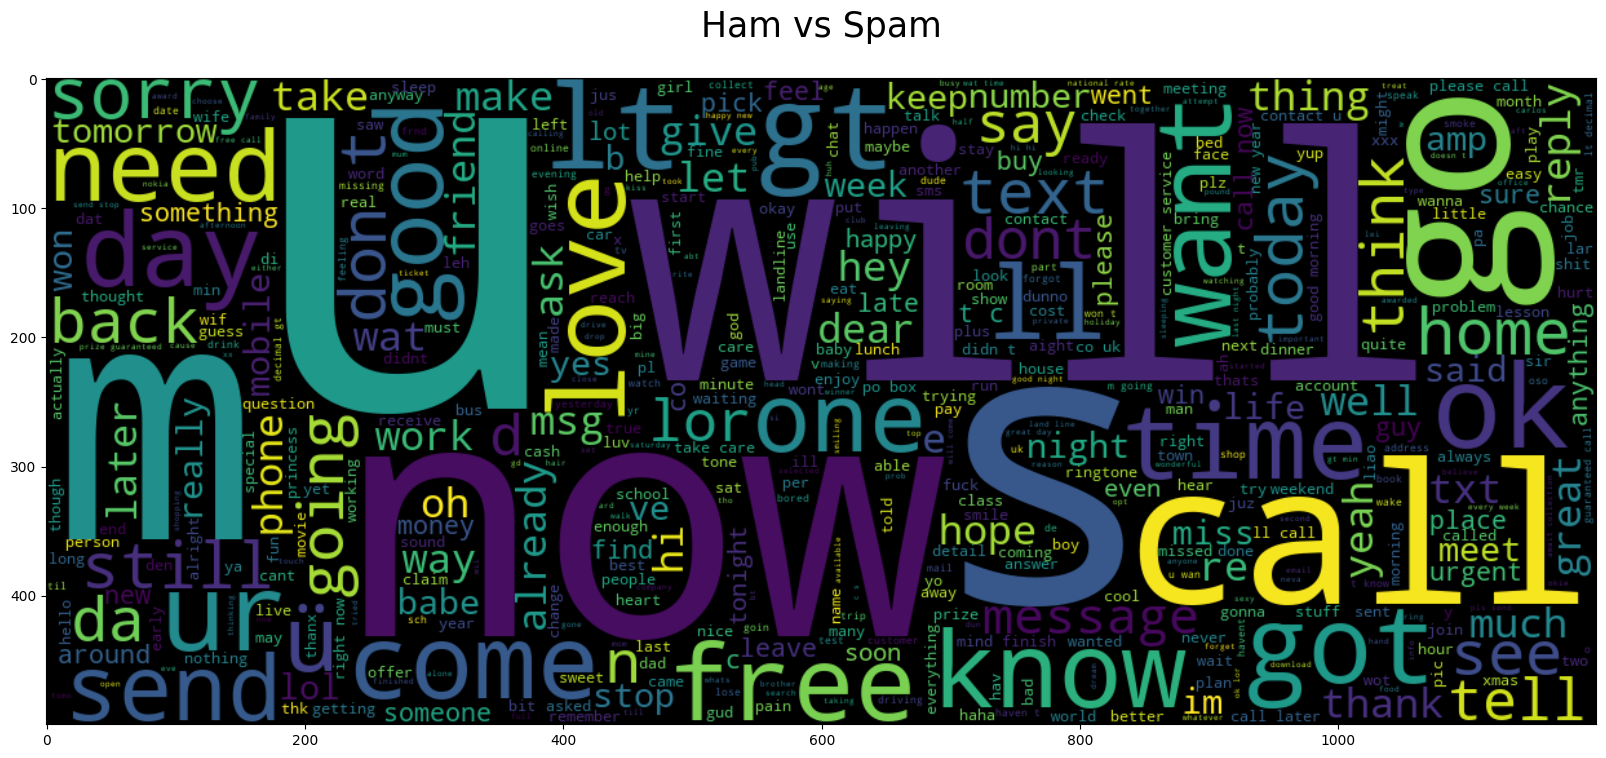

In [ ]:
msg_com=' '.join(df['Message'].dropna().astype(str).str.strip())

if not  msg_com.strip():
    print("no words found")
else:    
    plt.figure(figsize=(20,15),facecolor='None')
    wordcloud=WordCloud(max_words=500, width=1200, height=500).generate(msg_com)
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis=('off')
    plt.title("Ham vs Spam", fontsize=25, pad=30)
    plt.show() 

In [ ]:
x=df['Message']
y=df['Class']

In [ ]:
y

0       0
1       0
2       1
3       0
4       0
       ..
5569    1
5570    0
5571    0
5572    0
5573    0
Name: Class, Length: 5574, dtype: int64

In [ ]:
x_train,x_test,y_train,y_test=train_test_split(x,y,random_state=42,test_size=0.25)

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [ ]:
vector=TfidfVectorizer()
xv_train=vector.fit_transform(x_train)
xv_test=vector.transform(x_test)

In [ ]:
lr=LogisticRegression()
lr.fit(xv_train,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [ ]:
y_predict=lr.predict(xv_test)

In [ ]:
acc=accuracy_score(y_test,y_predict)
acc

0.9684361549497847

In [ ]:
pt=[]
for i in [lr]:
    i.fit(xv_train,y_train)
    pt.append(round(accuracy_score(y_test,i.predict(xv_test))*100,2))
print(pt)

[96.84]


In [ ]:
pd.set_option('display.max_colwidth',None)

In [ ]:
x.tail(4)

5570                                                                                              will ü b going to esplanade fr home
5571                                                                               pity was in mood for that so any other suggestions
5572    the guy did some bitching but i acted like i d be interested in buying something else next week and he gave it to us for free
5573                                                                                                        rofl its true to its name
Name: Message, dtype: object

In [ ]:
y.tail(4)

5570    0
5571    0
5572    0
5573    0
Name: Class, dtype: int64

In [ ]:
sample=["""pity was in mood for that so any other suggestions"""]
sample_vector=vector.transform(sample)
result=lr.predict(sample_vector)
print(result)
if (result == 0):
    print("Ham")
else:
    print("Spam")    
    

[0]
Ham


In [ ]:
corpus=["The cat on the mat",
        "The dog sat on the rug.",
        "Cats and dogs are great pets",
        "A cat and a dog play together."]

corpus_list=[doc.lower().replace('.','')for doc in corpus]
corpus_list

['the cat on the mat',
 'the dog sat on the rug',
 'cats and dogs are great pets',
 'a cat and a dog play together']

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
vec=CountVectorizer()
count=vec.fit_transform(corpus_list)
print(vec.vocabulary_)

{'the': 13, 'cat': 2, 'on': 8, 'mat': 7, 'dog': 4, 'sat': 12, 'rug': 11, 'cats': 3, 'and': 0, 'dogs': 5, 'are': 1, 'great': 6, 'pets': 9, 'play': 10, 'together': 14}


In [ ]:
df_ng=pd.DataFrame(
    count.toarray(),
    columns=vec.get_feature_names_out(),
    index=['Doc 1','Doc 2','Doc 3','Doc 4']
)
print(df_ng)

       and  are  cat  cats  dog  dogs  great  mat  on  pets  play  rug  sat  \
Doc 1    0    0    1     0    0     0      0    1   1     0     0    0    0   
Doc 2    0    0    0     0    1     0      0    0   1     0     0    1    1   
Doc 3    1    1    0     1    0     1      1    0   0     1     0    0    0   
Doc 4    1    0    1     0    1     0      0    0   0     0     1    0    0   

       the  together  
Doc 1    2         0  
Doc 2    2         0  
Doc 3    0         0  
Doc 4    0         1  


In [ ]:
import nltk
from nltk.corpus import treebank
nltk.download('treebank')
words=treebank.words()
words
clean=[w for w in words if  w not  in string.punctuation]

print(clean[:10])


[nltk_data] Downloading package treebank to
[nltk_data]     C:\Users\nabee\AppData\Roaming\nltk_data...
[nltk_data]   Package treebank is already up-to-date!


['Pierre', 'Vinken', '61', 'years', 'old', 'will', 'join', 'the', 'board', 'as']


In [ ]:
import nltk
from nltk.corpus import treebank
nltk.download('treebank')
sents=treebank.sents()
print
(sents)

[nltk_data] Downloading package treebank to
[nltk_data]     C:\Users\nabee\AppData\Roaming\nltk_data...
[nltk_data]   Package treebank is already up-to-date!


[['Pierre', 'Vinken', ',', '61', 'years', 'old', ',', 'will', 'join', 'the', 'board', 'as', 'a', 'nonexecutive', 'director', 'Nov.', '29', '.'], ['Mr.', 'Vinken', 'is', 'chairman', 'of', 'Elsevier', 'N.V.', ',', 'the', 'Dutch', 'publishing', 'group', '.'], ...]

In [ ]:
corpus=["My name is  Arjun,I am 30 years old"]
nltk.download('punkt_tab')
from nltk import word_tokenize,sent_tokenize
print(word_tokenize(corpus[0]))
print(sent_tokenize(corpus[0]))

In [ ]:
import nltk 
from nltk.stem.porter import PorterStemmer
porter=PorterStemmer()
words=['sleeping','walked','happiness','got']
for w in words:
    print(w,":",porter.stem(w))

In [ ]:
import nltk
from nltk.stem.snowball  import  SnowballStemmer()
snow=SnowballStemmer(language='english')
for w in words:
    print(w,":",snow.stem(w))

In [ ]:
from nltk.stem.lancaster import LancasterStemmer
lanca=LancasterStemmer()
for w in words:
    print(w,":",lanca.stem(w))

In [ ]:
from nltk.stem import WordNetLemmatizer
lem= WordNetLemmatizer()
nltk.download('wordnet')
nltk.download('omw-1.4')
for w in words:
    print(w,":",lem.lemmatize(w))